# Week 8: Ask simulated participants

To start, save a copy to your Drive (File → Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. You will need the course Gemini key, which the instructor shares in the first studio, and you can add it in the Secrets panel on the left as GEMINI_API_KEY. The outputs below are from one run with four chairs from the week 5 model and Gemini 3.8 Flash.

## 1. Setup

This reads your key and checks that Gemini accepts it. If it is not in the Secrets panel, it will ask you to paste it. MODEL is the Gemini model that answers as each persona.

In [1]:
import base64, collections, io, json, os, re, sys, time
import numpy as np, requests
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont, ImageOps

MODEL = "gemini-3.8-flash"  # the Gemini model that answers as each persona

def get_key(name):
    """A key from the environment, then from Colab's Secrets panel, then typed in."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        from getpass import getpass
        return getpass(name + ": ")

GEMINI_KEY = get_key("GEMINI_API_KEY")  # the course Gemini key
r = requests.get(f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}",
                 headers={"x-goog-api-key": GEMINI_KEY}, timeout=60)
if r.status_code != 200:
    raise RuntimeError(f"Gemini did not accept the key in GEMINI_API_KEY (error {r.status_code}). Check it in the Secrets panel.")

def gemini(url, body):
    """One call to the Gemini API. Waits and tries again if Gemini is busy."""
    for attempt in range(6):
        r = requests.post(url, headers={"x-goog-api-key": GEMINI_KEY}, json=body, timeout=180)
        if r.status_code not in (429, 500, 503):
            break
        print(f"  Gemini is busy (error {r.status_code}), trying again in {15 * (attempt + 1)} seconds")
        time.sleep(15 * (attempt + 1))
    r.raise_for_status()
    return r.json()

def font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        return ImageFont.load_default()
print("ready")

ready


## 2. The designs

With USE_EXAMPLE = True, DESIGNS has four chairs made by the week 5 model. To use your own, set it to False and run the cell again, and it will ask you to upload images of your designs. Two to six designs work best, and they are numbered in the order shown. Change SUBJECT to what your designs are, and PLACE to where they will be used.

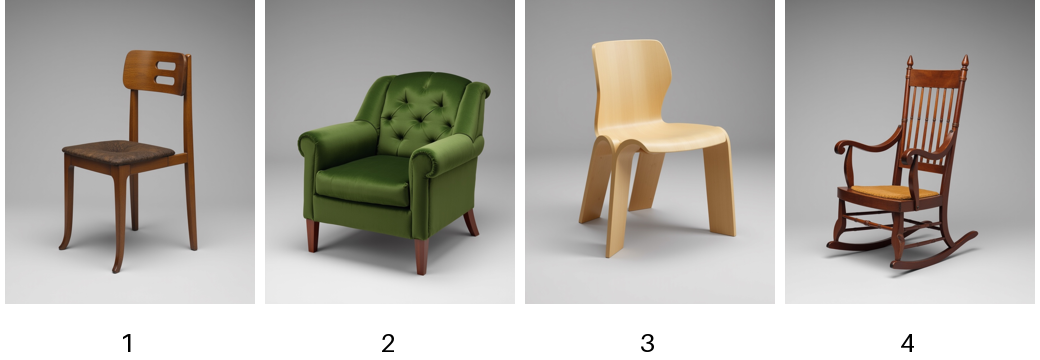

In [2]:
USE_EXAMPLE = True        # True: four chairs from the week 5 model. False: upload images of your own designs.
SUBJECT = "chair"         # what the designs are
PLACE = "the museum café" # where they will be used

if USE_EXAMPLE:
    base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/made/"
    DESIGNS = [Image.open(io.BytesIO(requests.get(f"{base}made-{i}.jpg", timeout=60).content)).convert("RGB") for i in range(4)]
else:
    from google.colab import files
    uploaded = files.upload()
    DESIGNS = []
    for name in sorted(uploaded):
        try:
            DESIGNS.append(ImageOps.exif_transpose(Image.open(io.BytesIO(uploaded[name]))).convert("RGB"))
            print(f"{SUBJECT} {len(DESIGNS)}: {name}")
        except Exception:
            print("skipped", name, "(not an image Colab can open)")

row = Image.new("RGB", (len(DESIGNS) * 260, 360), "white")
for i, im in enumerate(DESIGNS):
    t = im.copy(); t.thumbnail((250, 320)); row.paste(t, (i * 260 + (260 - t.width) // 2, 0))
    ImageDraw.Draw(row).text((i * 260 + 120, 326), str(i + 1), fill="black", font=font(26))
row

## 3. The personas and the question

Each persona is a short description of a person, and Gemini answers as that person. The personas borrow only the short seed descriptions from the generative agents in Park et al.'s paper, without their memory, planning or reflection. I wrote these personas for the museum café, so change them to the kinds of people your partner designs for, for example from your partner interviews. The last one has no description, so it shows what Gemini answers with no persona at all. QUESTION picks one of the QUESTIONS. "sit" and "buy" ask for one design and a reason, and "rate" asks for a rating of every design. For "rate", the pick is the design with the highest rating. You can also add your own question to QUESTIONS (a name that starts with "rate" asks for ratings). RUNS sets how many times each persona answers.

In [3]:
# Short descriptions for the museum café example, in the style of Park et al.'s seed descriptions.
PERSONAS = {
    "Ana": "You are Ana, a barista at the museum café. At closing you stack and wipe all the chairs, and on sunny days you carry them out to the terrace.",
    "Walter": "You are Walter, 74, a retired teacher who visits the museum every week and stays for coffee. You have a stiff back and use armrests to stand up.",
    "Mei": "You are Mei, who comes to the museum with a two-year-old. You need to sit down quickly and keep one hand free.",
    "Sam": "You are Sam, an architecture student who works on a laptop at the café for three or four hours at a time.",
    "Priya": "You are Priya, who buys the museum's furniture. You care about price, how long a chair lasts and whether it can be repaired.",
    "Lukas": "You are Lukas, a tourist on a short visit who stops at the café for ten minutes between galleries.",
    "No description": "You are a visitor at a museum café.",
}
QUESTIONS = {
    "sit": "Speaking as yourself, which chair would you want to sit on at the café, and why? "
           "Give the chair's number and a reason in two or three sentences.",
    "buy": "Speaking as yourself, which chair should the museum buy for the café, and why? "
           "Give the chair's number and a reason in two or three sentences.",
    "rate": "Speaking as yourself, rate how much you would want to sit on each chair at the café, from 1 (not at all) "
            "to 7 (very much). Give the ratings in chair order and a reason in two or three sentences.",
}
QUESTION = "sit"  # which of the QUESTIONS to ask
RUNS = 3          # how many times each persona answers

## 4. Ask

Each persona answers the question RUNS times. Every answer is saved to answers-QUESTION.json as soon as it comes back, so if the cell stops, you keep the answers you already have. If Gemini is busy, it waits and tries again. In the example, the 21 answers took about two minutes.

In [4]:
def image_part(img):
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=85)
    return {"inline_data": {"mime_type": "image/jpeg", "data": base64.b64encode(buf.getvalue()).decode()}}

PICK = {"type": "object", "properties": {"choice": {"type": "integer"}, "reason": {"type": "string"}},
        "required": ["choice", "reason"]}
RATE = {"type": "object", "properties": {"ratings": {"type": "array", "items": {"type": "integer"}},
        "reason": {"type": "string"}}, "required": ["ratings", "reason"]}

def ask(persona, question):
    """One persona's answer. A question whose name starts with "rate" asks for a rating of every design,
    and its pick is the design rated highest."""
    parts = [{"text": f"{persona} Here are {len(DESIGNS)} {SUBJECT} designs for {PLACE}."}]
    for i, im in enumerate(DESIGNS):
        parts += [{"text": f"{SUBJECT.capitalize()} {i + 1}:"}, image_part(im)]
    parts.append({"text": QUESTIONS[question]})
    rating = question.startswith("rate")
    body = {"contents": [{"role": "user", "parts": parts}],
            "generationConfig": {"temperature": 1.0, "responseMimeType": "application/json",
                                 "responseSchema": RATE if rating else PICK}}
    a = json.loads(gemini(f"https://generativelanguage.googleapis.com/v1beta/models/{MODEL}:generateContent",
                          body)["candidates"][0]["content"]["parts"][0]["text"])
    if rating:
        a["choice"] = int(np.argmax(a["ratings"])) + 1
    return a

answers = []
for name, persona in PERSONAS.items():
    for run in range(RUNS):
        a = ask(persona, QUESTION)
        answers.append({"persona": name, "run": run + 1, "question": QUESTIONS[QUESTION], **a})
        json.dump(answers, open(f"answers-{QUESTION}.json", "w"), indent=1)  # saved after every answer
        extra = f" (ratings {a['ratings']})" if "ratings" in a else ""
        print(f"{name}, run {run + 1}: {SUBJECT} {a['choice']}{extra}. {a['reason']}")

Ana, run 1: chair 2. As a customer visiting the café, I would choose Chair 2 because its deep plush cushioning and supportive armrests offer the ultimate cozy comfort. It looks like an exceptionally inviting spot to unwind, read, and slowly savor a cup of coffee. The luxurious velvet upholstery provides a relaxing, lounge-like experience that makes you want to stay a while.


Ana, run 2: chair 2. If I were sitting down at the café, I would choose Chair 2 for its luxurious comfort and inviting design. The plush, button-tufted upholstery and supportive armrests make it the ultimate cozy spot to unwind with a warm drink and a book. It offers far more relaxation and indulgence for a café visit than the rigid wooden options.


Ana, run 3: chair 2. I would choose Chair 2 because its plush velvet upholstery, padded back, and supportive armrests offer the most comfort for relaxing with a drink. Unlike the rigid wooden chairs, it invites you to settle in and enjoy a cozy, leisurely café experience.


Walter, run 1: chair 2. At my age, having sturdy, padded armrests makes all the difference when I need to push myself up to stand. The cushioned, upright back will give my stiff back comfortable support while I enjoy my weekly coffee, unlike the armless chairs or the unsteady rocking chair.


Walter, run 2: chair 2. With my stiff back, I need solid support and sturdy armrests to help me push myself up comfortably when it is time to leave. This armchair offers supportive cushioning and stable legs, unlike the armless options or the unsteady rocking chair.


Walter, run 3: chair 2. With my stiff back, I need a stable armchair that won't shift around when I try to get up. The sturdy armrests and solid legs on this armchair give me the firm support I need to push myself up comfortably after enjoying my coffee.


... (11 outputs left out)

Lukas, run 3: chair 1. Since I only have ten minutes to grab a quick coffee between galleries, Chair 1 is the most practical choice. Its light frame and gently padded seat offer just the right amount of comfort to rest my legs without sinking in so deeply that getting back up feels like a chore. It fits the pace of a brief museum pit stop perfectly.


No description, run 1: chair 2. After spending hours on my feet exploring the museum galleries, sinking into this plush, upholstered armchair would offer the ultimate restful break. The deep cushion, soft velvet fabric, and supportive armrests create a cozy, luxurious spot to enjoy a coffee and recharge.


No description, run 2: chair 2. After spending hours on my feet touring the museum galleries, Chair 2 looks like the ultimate spot to sink in and relax. Its plush cushioning and supportive armrests provide maximum comfort for resting weary legs while enjoying a coffee.


No description, run 3: chair 2. After spending hours on my feet touring the museum galleries, this plush, upholstered armchair provides the ultimate comfort to sink into and rest. The supportive armrests and deeply cushioned seat make it the most inviting spot to relax and enjoy a warm beverage.


## 5. Compare

This prints which design each persona picked in each run. Then it compares every run of each persona with every run of the persona with no description, and counts how often their picks match. For example, if a persona picks chair 1 in all three runs and the no-description persona picks chairs 1, 2 and 3, they match in 3 of 9 pairs. The no-description persona is also compared with its own runs. If a persona matches in about the same share of pairs as the no-description persona does against itself, the description did not change the pick much. Last, it encodes every reason as an embedding with Gemini's embedding model and compares them with cosine similarity. In the heatmap, each cell is one pair of answers, grouped by persona, and a darker cell means the two reasons are more similar.

Chair picked in each run:
  Ana             [2, 2, 2]
  Walter          [2, 2, 2]
  Mei             [1, 1, 1]
  Sam             [1, 1, 1]
  Priya           [2, 2, 2]
  Lukas           [1, 1, 1]
  No description  [2, 2, 2]

How often each persona's picks match the No description persona's picks, every run against every run:
  Ana             9 of 9
  Walter          9 of 9
  Mei             0 of 9
  Sam             0 of 9
  Priya           9 of 9
  Lukas           0 of 9
  No description  3 of 3 (against itself)



similarity of two answers by the same persona: 0.93
similarity of two answers by different personas: 0.76
similarity of each persona's own answers:
  Ana             0.94
  Walter          0.90
  Mei             0.92
  Sam             0.96
  Priya           0.93
  Lukas           0.95
  No description  0.89


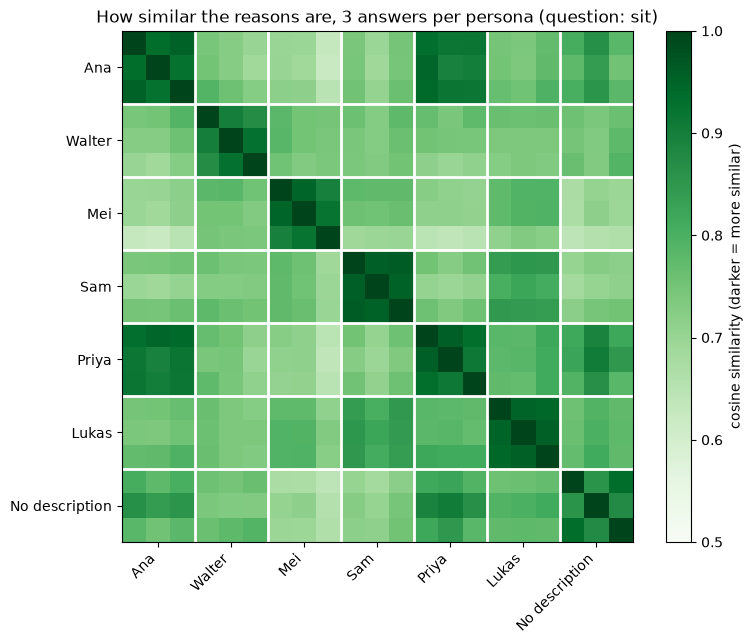

In [5]:
names = list(PERSONAS)
picks = {n: [a["choice"] for a in answers if a["persona"] == n] for n in names}
print(f"{SUBJECT.capitalize()} picked in each run:")
for n in names:
    print(f"  {n:15s} {picks[n]}")

BASE = "No description"
if BASE in picks:
    print(f"\nHow often each persona's picks match the {BASE} persona's picks, every run against every run:")
    b = picks[BASE]
    for n in names:
        if n == BASE:
            pairs = [(x, y) for i, x in enumerate(b) for y in b[i + 1:]]
            print(f"  {n:15s} {sum(x == y for x, y in pairs)} of {len(pairs)} (against itself)")
        else:
            print(f"  {n:15s} {sum(x == y for x in picks[n] for y in b)} of {len(picks[n]) * len(b)}")

def embed(texts):
    url = "https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents"
    j = gemini(url, {"requests": [{"model": "models/gemini-embedding-001", "content": {"parts": [{"text": t}]}}
                                  for t in texts]})
    E = np.array([e["values"] for e in j["embeddings"]])
    return E / np.linalg.norm(E, axis=1, keepdims=True)

E = embed([a["reason"] for a in answers])
S = E @ E.T
who = [a["persona"] for a in answers]
same = [S[i, j] for i in range(len(who)) for j in range(i + 1, len(who)) if who[i] == who[j]]
other = [S[i, j] for i in range(len(who)) for j in range(i + 1, len(who)) if who[i] != who[j]]
print(f"\nsimilarity of two answers by the same persona: {np.mean(same):.2f}")
print(f"similarity of two answers by different personas: {np.mean(other):.2f}")
print("similarity of each persona's own answers:")
for n in names:
    idx = [i for i, w in enumerate(who) if w == n]
    pairs = [S[i, j] for k, i in enumerate(idx) for j in idx[k + 1:]]
    if pairs:
        print(f"  {n:15s} {np.mean(pairs):.2f}")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(S, vmin=0.5, vmax=1, cmap="Greens")
ticks = [i * RUNS + (RUNS - 1) / 2 for i in range(len(names))]
ax.set_xticks(ticks); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(ticks); ax.set_yticklabels(names)
for k in range(1, len(names)):
    ax.axhline(k * RUNS - 0.5, color="white", lw=2); ax.axvline(k * RUNS - 0.5, color="white", lw=2)
ax.set_title(f"How similar the reasons are, {RUNS} answers per persona (question: {QUESTION})")
fig.colorbar(im, ax=ax, label="cosine similarity (darker = more similar)")
plt.tight_layout(); plt.savefig(f"similarity-{QUESTION}.png", dpi=150); plt.show()

## 6. Repeated words

This counts the words used in the most answers. If the same few words come back for every persona, the answers do not tell you much about how these people differ. To see how much the question changes the answers, as in today's slides, set QUESTION to another question and run sections 3 to 6 again.

In [6]:
STOP = set("a an the and or of to in on for with it is i my me this that would be at as so can its it's "
           "one which because want sit also very more than but have like just".split())
STOP |= {SUBJECT, SUBJECT + "s"} | set(re.findall(r"[a-zé']+", PLACE.lower())) | {"cafe"}
words = collections.Counter()
for a in answers:
    words.update(set(w for w in re.findall(r"[a-zé']+", a["reason"].lower()) if w not in STOP and len(w) > 2))
print(f"Words used in the most answers (out of {len(answers)}):")
for w, n in words.most_common(12):
    print(f"  {w:14s} {n}")

Words used in the most answers (out of 21):
  armrests       14
  comfort        9
  plush          9
  supportive     9
  coffee         8
  while          8
  back           8
  provides       7
  spot           7
  without        7
  seat           7
  galleries      7


## 7. Your partners' picks

In your partner tests, ask your partner's designers the same question you gave the personas. Then type which design each of them picked in PARTNER_PICKS, for example PARTNER_PICKS = {"Designer 1": 3, "Designer 2": 1}, and run this cell again. It puts their picks next to the simulated ones. Mark where the two agree and where they differ, and compare your designers' reasons with the reasons above.

In [7]:
# After your partner tests, type which design each of your partner's designers picked, for example
# PARTNER_PICKS = {"Designer 1": 3, "Designer 2": 1}
PARTNER_PICKS = {}

if not PARTNER_PICKS:
    print("Add your partners' picks to PARTNER_PICKS after your partner tests, and run this cell again.")
else:
    sim = collections.Counter(a["choice"] for a in answers)
    real = collections.Counter(PARTNER_PICKS.values())
    for i in range(1, len(DESIGNS) + 1):
        print(f"{SUBJECT} {i}: {sim[i]} of {len(answers)} simulated picks, {real[i]} of {len(PARTNER_PICKS)} partner picks")
    for person, pick in PARTNER_PICKS.items():
        print(f"{person} picked {SUBJECT} {pick}")

Add your partners' picks to PARTNER_PICKS after your partner tests, and run this cell again.
